# 01 — Memahami Data

Notebook ini menjawab pertanyaan paling dasar sebelum menghitung apa pun:

1. Data apa yang kita punya?
2. Apakah data itu satu hari atau banyak hari?
3. Kolom apa yang bisa dipercaya, dan apa yang tidak boleh dihitung?

**Penting:** snapshot IDX di proyek ini hanya **satu hari**. Data historis Yahoo Finance
dipakai untuk tren, return, dan risiko. Jangan mencampur keduanya tanpa menjelaskan bedanya.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if (ROOT / "notebooks").exists():
    pass
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Root proyek:", ROOT)

Root proyek: C:\Users\53\Documents\data sains\project saham


## 1. Snapshot harian IDX

File mentah dibaca apa adanya. Kita belum mengubah file di `data/raw`.

In [2]:
from src.data_loader import load_snapshot

snapshot_raw = load_snapshot()
print("Ukuran:", snapshot_raw.shape)
snapshot_raw.head(3)

Ukuran: (963, 28)


,No,Kode Saham,Nama Perusahaan,Remarks,Sebelumnya,Open Price,Tanggal Perdagangan Terakhir,First Trade,Tertinggi,Terendah,Penutupan,Selisih,Volume,Nilai,Frekuensi,Index Individual,Offer,Offer Volume,Bid,Bid Volume,Listed Shares,Tradeble Shares,Weight For Index,Foreign Sell,Foreign Buy,Non Regular Volume,Non Regular Value,Non Regular Frequency
0,1,AADI,Adaro Andalan Indonesia Tbk.,--MO1SD0F70000A121------------,11300,11300,23 Okt 2026,11325,11800,11225,11375,75,10571100,121943830000,9112,205.0,11400,10500,11375,164600,7786891760,7786891760,1415656922,5317700,2901600,712,7980250,13
1,2,AALI,Astra Agro Lestari Tbk.,XDMO113E100200D232------------,9150,9150,23 Okt 2026,9150,9800,9150,9625,475,8207400,78525875000,4192,781.9,9625,277300,9600,23100,1924688333,1924688333,390134325,673600,4617700,0,0,0
2,3,ABBA,Mahaka Media Tbk.,--U-4100000000E614-E---------X,30,0,23 Okt 2026,0,0,0,30,0,0,0,0,66.3,0,0,0,0,3935892857,3935892857,1297663875,0,0,0,0,0


In [3]:
# Nama kolom asli dari file IDX
for i, column in enumerate(snapshot_raw.columns, start=1):
    print(f"{i:2d}. {column}")

 1. No
 2. Kode Saham
 3. Nama Perusahaan
 4. Remarks
 5. Sebelumnya
 6. Open Price
 7. Tanggal Perdagangan Terakhir
 8. First Trade
 9. Tertinggi
10. Terendah
11. Penutupan
12. Selisih
13. Volume
14. Nilai
15. Frekuensi
16. Index Individual
17. Offer
18. Offer Volume
19. Bid
20. Bid Volume
21. Listed Shares
22. Tradeble Shares
23. Weight For Index
24. Foreign Sell
25. Foreign Buy
26. Non Regular Volume
27. Non Regular Value
28. Non Regular Frequency


## 2. Kualitas snapshot

Kita cek tanggal, missing value, duplikat, saham tanpa transaksi, dan Open Price = 0.

In [4]:
from src.data_cleaning import clean_snapshot, snapshot_quality_report

snapshot = clean_snapshot(snapshot_raw)
report = snapshot_quality_report(snapshot_raw, snapshot)

for key in [
    "rows", "columns", "unique_tickers", "dates", "missing_values",
    "duplicate_rows", "duplicate_tickers", "no_trade_rows",
    "traded_rows", "zero_open_traded_rows", "invalid_ohlc_rows", "total_value",
]:
    print(f"{key:24s}: {report[key]}")

print("\nPeringatan:")
for warning in report["warnings"]:
    print("-", warning)

rows                    : 963
columns                 : 28
unique_tickers          : 963
dates                   : ['2026-10-23']
missing_values          : 0
duplicate_rows          : 0
duplicate_tickers       : 0
no_trade_rows           : 130
traded_rows             : 833
zero_open_traded_rows   : 204
invalid_ohlc_rows       : 0
total_value             : 13915556599600.0

Peringatan:
- Data hanya mencakup satu tanggal. Grafik tren, return historis, dan risiko tidak boleh dihitung dari snapshot ini.
- 130 saham tidak memiliki volume transaksi pada tanggal tersebut; harga penutupan bisa merupakan harga terakhir sebelumnya.
- 204 saham diperdagangkan tetapi Open Price tercatat 0. Nilai tersebut diperlakukan sebagai data tidak tersedia, bukan harga nol.


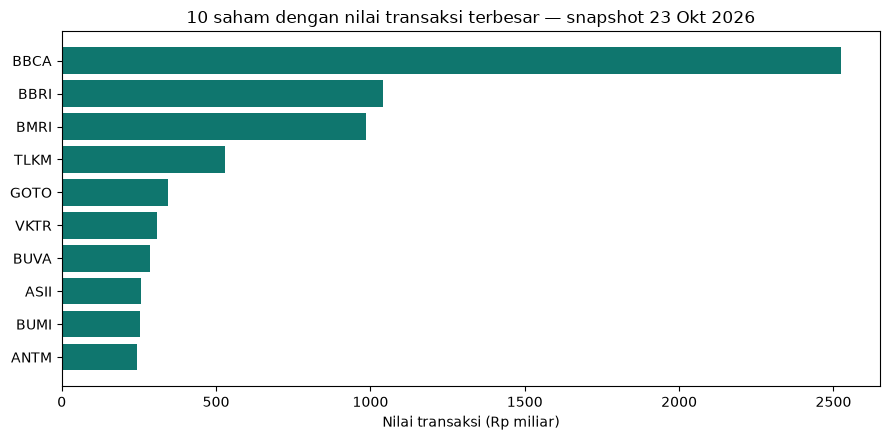

In [5]:
top_value = snapshot.nlargest(10, "value").sort_values("value")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top_value["ticker"], top_value["value"] / 1e9, color="#0F766E")
ax.set_xlabel("Nilai transaksi (Rp miliar)")
ax.set_title("10 saham dengan nilai transaksi terbesar — snapshot 23 Okt 2026")
plt.tight_layout()
plt.show()

**Cara membaca:** nilai transaksi besar menunjukkan aktivitas pada hari itu, bukan kualitas
perusahaan dan bukan prediksi harga besok. Snapshot satu hari tidak punya informasi tren.

## 3. Data historis

Data ini memiliki banyak tanggal per saham. Kolom `adj_close` dipakai untuk return jangka panjang.

In [6]:
from src.data_loader import load_historical_prices

prices_raw = load_historical_prices()
print("Ukuran:", prices_raw.shape)
print("Jumlah ticker:", prices_raw["ticker"].nunique())
print("Rentang:", prices_raw["date"].min().date(), "s/d", prices_raw["date"].max().date())
prices_raw.head(3)

Ukuran: (23856, 8)
Jumlah ticker: 13
Rentang: 2019-01-01 s/d 2026-10-26


,date,ticker,open,high,low,close,adj_close,volume
0,2019-01-01,ADRO.JK,1215.0,1215.0,1215.0,1215.0,318.382202,0
1,2019-01-02,ADRO.JK,1215.0,1225.0,1215.0,1225.0,321.002655,17086200
2,2019-01-03,ADRO.JK,1225.0,1235.0,1215.0,1230.0,322.312866,26738400


In [7]:
from src.data_cleaning import clean_historical, historical_quality_report

prices = clean_historical(prices_raw)
quality = historical_quality_report(prices)
print("Baris bersih:", quality["rows"])
print("Ticker:", quality["tickers"])
print("Missing:", quality["missing_values"])
print("Duplikat:", quality["duplicate_rows"])
print("OHLC tidak wajar:", quality["invalid_ohlc_rows"])
print("Volume nol:", quality["zero_volume_rows"])
quality["per_ticker"]

Baris bersih: 23856
Ticker: 13
Missing: 0
Duplikat: 0
OHLC tidak wajar: 0
Volume nol: 164


,Ticker,Baris,Awal,Akhir,Kelengkapan (%),Missing,Duplikat,OHLC Tidak Wajar,Volume Nol,Harga Disesuaikan Berbeda (%),Jeda > 5 Hari
0,ADRO.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,14,93.6,10
1,AKRA.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,15,96.9,10
2,ANTM.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,13,95.3,10
3,ASII.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,14,99.5,10
4,BBCA.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,15,97.8,10
5,BBRI.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,13,93.4,10
6,BMRI.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,14,98.5,10
7,GOTO.JK,1085,2022-04-11,2026-10-26,57.1,0,0,0,3,0.0,7
8,ICBP.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,13,95.9,10
9,SMGR.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,14,94.4,10


## 4. Kenapa satu hari tidak cukup?

- **Return** butuh minimal dua harga.
- **Volatilitas** butuh banyak return harian.
- **Maximum drawdown** butuh rangkaian harga dari puncak ke lembah.
- **Korelasi** butuh pasangan return pada tanggal yang sama.

Karena itu, grafik performa dan risiko di dashboard selalu memakai data historis, bukan snapshot.

In [8]:
# Contoh: berapa hari data yang tersedia per ticker?
prices.groupby("ticker").agg(
    hari=("date", "nunique"),
    awal=("date", "min"),
    akhir=("date", "max"),
).sort_values("hari", ascending=False)

,hari,awal,akhir
ticker,,,
AKRA.JK,1899,2019-01-01,2026-10-26
BBCA.JK,1899,2019-01-01,2026-10-26
ANTM.JK,1899,2019-01-01,2026-10-26
BMRI.JK,1899,2019-01-01,2026-10-26
BBRI.JK,1899,2019-01-01,2026-10-26
UNVR.JK,1899,2019-01-01,2026-10-26
SMGR.JK,1899,2019-01-01,2026-10-26
ASII.JK,1898,2019-01-01,2026-10-26
ADRO.JK,1898,2019-01-01,2026-10-26


## Kesimpulan

- Snapshot menjawab “apa yang terjadi pada satu tanggal”.
- Data historis menjawab “bagaimana perjalanannya selama beberapa tahun”.
- Keduanya punya keterbatasan. Sumber pihak ketiga tetap perlu diverifikasi.

Lanjut ke `02_data_cleaning.ipynb` untuk melihat proses pembersihan secara lebih rinci.